In [ ]:
import numpy as np
import pandas as pd

In [2]:
df_train = pd.read_csv("/kaggle/input/digit-recognizer/train.csv")
df_test = pd.read_csv("/kaggle/input/digit-recognizer/test.csv")

print(df_test.shape)
print(df_train.shape)
df_train.head()

(28000, 784)
(42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


5


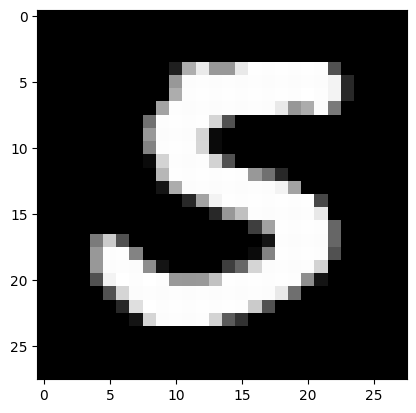

In [3]:
# show an image from the dataset

import matplotlib.pyplot as plt


print(df_train.iloc[99, 0])
plt.imshow(df_train.iloc[99, 1:].values.reshape(28, 28), cmap='gray')

Split the data

In [4]:
from sklearn.model_selection import train_test_split


data_train, data_val = train_test_split(df_train, test_size=0.10, random_state=42, stratify=df_train["label"])

data_train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
27053,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
33380,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20034,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20793,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3214,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Create dataset

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
import cv2


class CustomDataset(Dataset):
    def __init__(self, dataset, transform=None, is_test=False):

        self.data = dataset
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        if self.is_test == False:
            label = self.data.iloc[idx, 0]
            image = self.data.iloc[idx, 1:].values.reshape(28, 28).astype('uint8')
        else:
            label = 'None'
            image = self.data.iloc[idx, :].values.reshape(28, 28).astype('uint8')     

        if self.transform != None:
            image = self.transform(image)
            
        return image, label
         

In [ ]:
import random
from PIL import Image


class RandomEraseDigitPart:
    def __init__(self, erase_size=5, p=0.5):
        """
        erase_size: number of pixels to erase (approximate size of the patch)
        p: probability of applying the transform
        """
        self.erase_size = erase_size
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img

        img_np = np.array(img)

        # Get coordinates of non-zero pixels
        coords = np.argwhere(img_np > 0)

        if len(coords) == 0:
            return img

        # Pick a random pixel belonging to the digit
        y, x = coords[random.randint(0, len(coords) - 1)]

        # Calculate patch boundaries
        half = self.erase_size // 2

        y_min = max(0, y - half)
        y_max = min(img_np.shape[0], y + half)

        x_min = max(0, x - half)
        x_max = min(img_np.shape[1], x + half)

        # Erase the patch
        img_np[y_min:y_max, x_min:x_max] = 0

        return Image.fromarray(img_np.astype(np.uint8))



In [ ]:
import cv2


class RandomMorphology:
    def __init__(self, mode="erosion", kernel_size=3, p=0.5):
        self.mode = mode
        self.se = cv2.MORPH_CROSS
        self.kernel = cv2.getStructuringElement(self.se, (kernel_size, kernel_size))
        self.p = p

    def __call__(self, img):
        if np.random.rand() > self.p:
            return img

        img = np.array(img)

        if self.mode == "erosion":
            img = cv2.erode(img, self.kernel)
        elif self.mode == "dilation":
            img = cv2.dilate(img, self.kernel)

        return Image.fromarray(img.astype(np.uint8))



In [ ]:
# define transformations, create dataset and dataloaders

transform_train = transforms.Compose([
                          transforms.ToPILImage(),
                          RandomEraseDigitPart(erase_size=4, p=0.4),
                          RandomMorphology(mode='dilation', kernel_size=3, p=0.1),
                          transforms.RandomApply([transforms.RandomAffine(degrees=(-10, 10), translate=(0.04, 0.04), scale=(0.9, 1.1))], p=0.6),
                          # transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=0.03)], p=0.3),
                          transforms.ToTensor(),
                          transforms.Normalize((0.5,), (0.5,))
            ])

transform = transforms.Compose([
                          transforms.ToPILImage(),
                          transforms.ToTensor(),
                          transforms.Normalize((0.5,), (0.5,))
            ])

train_set = CustomDataset(data_train, transform_train)
val_set = CustomDataset(data_val, transform)
test_set = CustomDataset(df_test, transform, is_test=True)

batch = 64
train_loader = DataLoader(train_set, batch_size=batch, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch, shuffle=False)

3


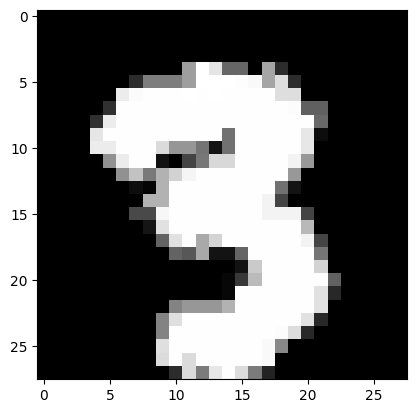

In [9]:
# show transformed image

im, lab = train_set[0]
print(lab)
plt.imshow(im.permute(1, 2, 0), cmap='gray')

tensor([9, 1, 3, 7, 5, 3, 9, 7, 7, 1, 9, 1, 5, 6, 4, 1, 4, 1, 9, 6, 0, 8, 2, 5,
        1, 0, 9, 0, 1, 6, 9, 7, 5, 5, 8, 5, 0, 8, 6, 1, 5, 3, 7, 9, 5, 8, 2, 2,
        7, 0, 7, 5, 3, 9, 4, 9, 0, 0, 7, 9, 4, 8, 4, 5])


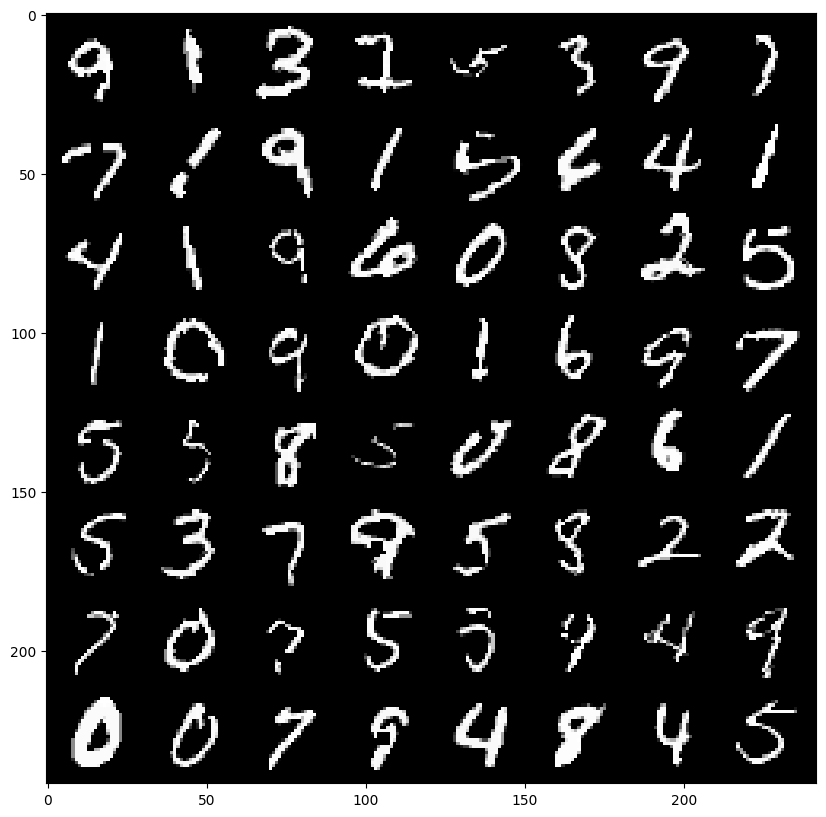

In [10]:
# show one train batch

import torchvision


def imshow(img):
    npimg = img.numpy()
    plt.figure(figsize=(10, 10))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(train_loader)

images, labels = next(dataiter)

print(labels)
imshow(torchvision.utils.make_grid(images))

('None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None')


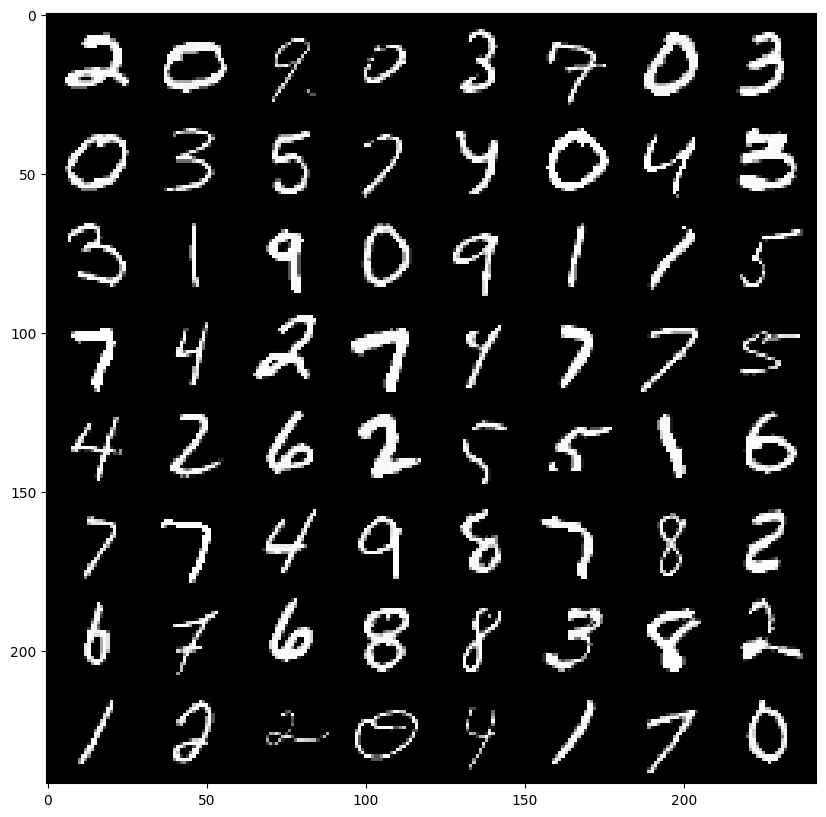

In [11]:
# show one test batch

dataiter = iter(test_loader)

images, labels = next(dataiter)

print(labels)
imshow(torchvision.utils.make_grid(images))

In [12]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


Create and train the model

In [ ]:
import torch.nn as nn


class Network(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3)    # 28-3+1=26
        self.bn1 = nn.BatchNorm2d(16)
        self.act1 = nn.ReLU()
        # self.pool1 = nn.MaxPool2d(2) # (28-2)/2+1=14
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(32)
        self.act2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2) # 7
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(64)
        self.act3 = nn.ReLU()
        # self.pool3 = nn.MaxPool2d(2) # 3
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3)
        self.bn4 = nn.BatchNorm2d(128)
        self.act4 = nn.ReLU()
        # self.pool4 = nn.MaxPool2d(2) # 1
        self.conv5 = nn.Conv2d(128, 128, kernel_size=3)
        self.bn5 = nn.BatchNorm2d(128)
        self.act5 = nn.ReLU()
        self.fc1 = nn.Linear(128 * 6 * 6, 256)
        self.actL = nn.ReLU()
        self.dropout_fc1 = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(256, 10)
        # self.act4 = nn.Softmax(dim=1)
        

    def forward(self, x):
        out = self.act1(self.bn1(self.conv1(x)))
        out = self.pool2(self.act2(self.bn2(self.conv2(out))))
        out = self.act3(self.bn3(self.conv3(out)))
        out = self.act4(self.bn4(self.conv4(out)))
        out = self.act5(self.bn5(self.conv5(out)))
        out = out.view(out.size(0), -1)
        out = self.dropout_fc1(self.actL(self.fc1(out)))
        out = self.fc2(out)

        return out
    

Net = Network().to(device)

In [14]:
# loss function and optimization

import torch.optim as optim


criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(Net.parameters(), lr=1e-3, weight_decay=5e-5)

lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=5, mode='min', min_lr=1e-6, verbose=True)

In [ ]:
# training

model_path = "./model.pth"

epoch_loss_list = []
epoch_loss_list_val = []
epoch_acc_list = []
epoch_acc_list_val = []

best_score = -float("inf")
non_improved_epoch = 0

for epoch in range(50):

    Net.train()
    
    total_loss = 0
    total_loss_val = 0
    epoch_loss = 0
    epoch_loss_val = 0
    epoch_accuracy = 0
    epoch_accuracy_val = 0
    correct = 0
    total = 0

    for i, data in enumerate(train_loader, 0):

        images, labels = data
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = Net(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        # train loss and acc
        total_loss += loss.item()
        epoch_loss = total_loss/len(train_loader)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_accuracy = correct/total*100.
    epoch_loss_list.append(epoch_loss)
    epoch_acc_list.append(epoch_accuracy)

    # Validation
    Net.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():

        for i, data in enumerate(val_loader, 0):

            images, labels = data
            images = images.to(device)
            labels = labels.to(device)

            outputs = Net(images)

            loss_val = criterion(outputs, labels)

            total_loss_val += loss_val.item()
            epoch_loss_val = total_loss_val/len(val_loader)

            _, predicted = torch.max(outputs, 1)

            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

        lr_scheduler.step(epoch_loss_val)

        epoch_accuracy_val = correct_val/total_val*100.

        # add to list for later plotting
        epoch_loss_list_val.append(epoch_loss_val)
        epoch_acc_list_val.append(epoch_accuracy_val)

        # save the best model
        new_score = epoch_accuracy_val
        if new_score > best_score:
            best_score = new_score
            non_improved_epoch = 0

            torch.save({"model": Net.state_dict(), 
                        "optimizer": optimizer.state_dict(), 
                        "best_score": best_score, 
                        "epoch": epoch, 
                        "lr_scheduler": lr_scheduler.state_dict()}, model_path)
        else:
            non_improved_epoch += 1
            
        if non_improved_epoch > 10:
            print("Early stopping")
            break

    print("{}. Epoch\nEpoch loss: {:.8f}\nAccuracy: {:.2f}%\nEpoch loss on validation set: {:.8f}\nAccuracy on validation set: {:.2f}%".format(epoch, epoch_loss, epoch_accuracy, epoch_loss_val, epoch_accuracy_val))
    print("-"*10)

print('Finished')

0. Epoch
Epoch loss: 0.18263029
Accuracy: 94.25%
Epoch loss on validation set: 0.06112732
Accuracy on validation set: 98.24%
----------
1. Epoch
Epoch loss: 0.09154653
Accuracy: 97.16%
Epoch loss on validation set: 0.04262634
Accuracy on validation set: 98.50%
----------
2. Epoch
Epoch loss: 0.07489670
Accuracy: 97.71%
Epoch loss on validation set: 0.04253383
Accuracy on validation set: 98.79%
----------
3. Epoch
Epoch loss: 0.06730139
Accuracy: 97.93%
Epoch loss on validation set: 0.04206653
Accuracy on validation set: 98.98%
----------
4. Epoch
Epoch loss: 0.06153587
Accuracy: 98.02%
Epoch loss on validation set: 0.03151270
Accuracy on validation set: 99.07%
----------
5. Epoch
Epoch loss: 0.05765797
Accuracy: 98.33%
Epoch loss on validation set: 0.03424375
Accuracy on validation set: 99.12%
----------
6. Epoch
Epoch loss: 0.05170653
Accuracy: 98.47%
Epoch loss on validation set: 0.03599385
Accuracy on validation set: 98.98%
----------
7. Epoch
Epoch loss: 0.04941090
Accuracy: 98.41%

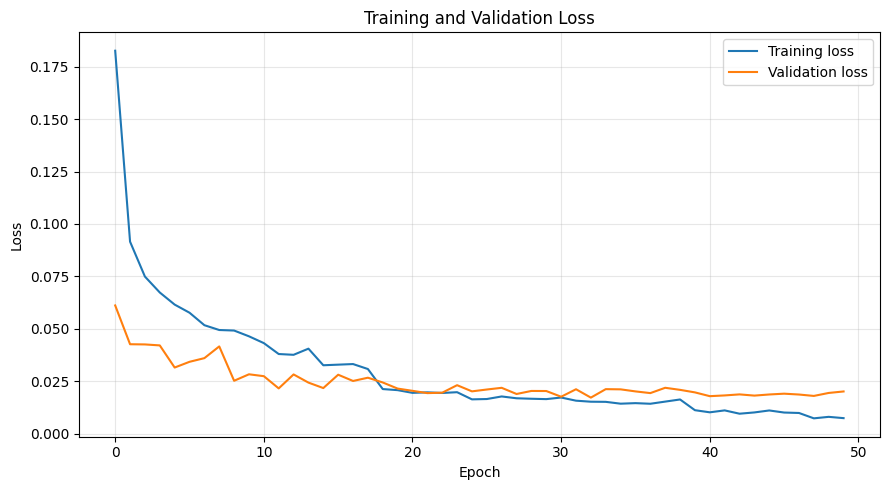

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(epoch_loss_list, label='Training loss')
plt.plot(epoch_loss_list_val, label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

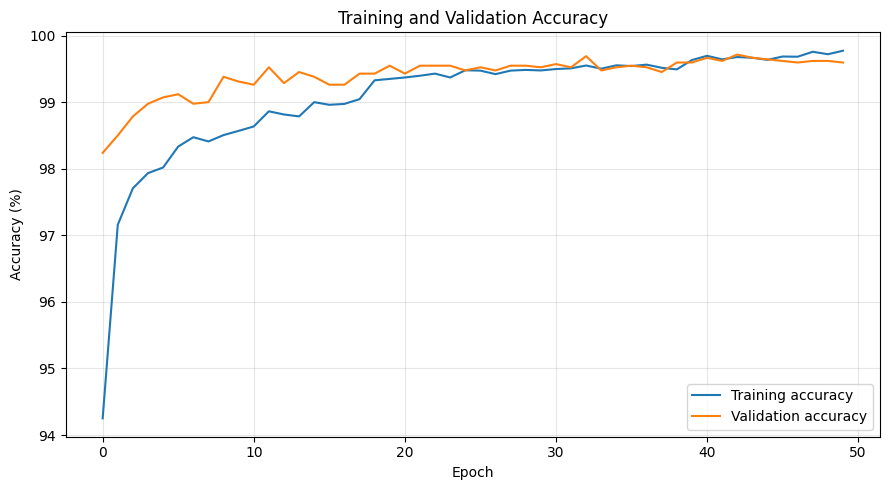

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(epoch_acc_list, label='Training accuracy')
plt.plot(epoch_acc_list_val, label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

In [18]:
# load the best model checkpoint

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

Net.load_state_dict(checkpoint["model"])
Net.eval()

print(f"Best validation accuracy: {checkpoint['best_score']:.2f}%")
print(f"Best epoch: {checkpoint['epoch']}")

Best validation accuracy: 99.71%
Best epoch: 42


/opt/conda/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [19]:
# collect validation predictions

all_predictions = []
all_labels = []
misclassified_images = []
misclassified_labels = []
misclassified_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = Net(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

        # find incorrectly classified images
        incorrect = predicted.cpu() != labels

        for i in torch.where(incorrect)[0]:

            if len(misclassified_images) < 20:

                misclassified_images.append(images[i].cpu())

                misclassified_labels.append(labels[i].item())

                misclassified_predictions.append(predicted[i].item())

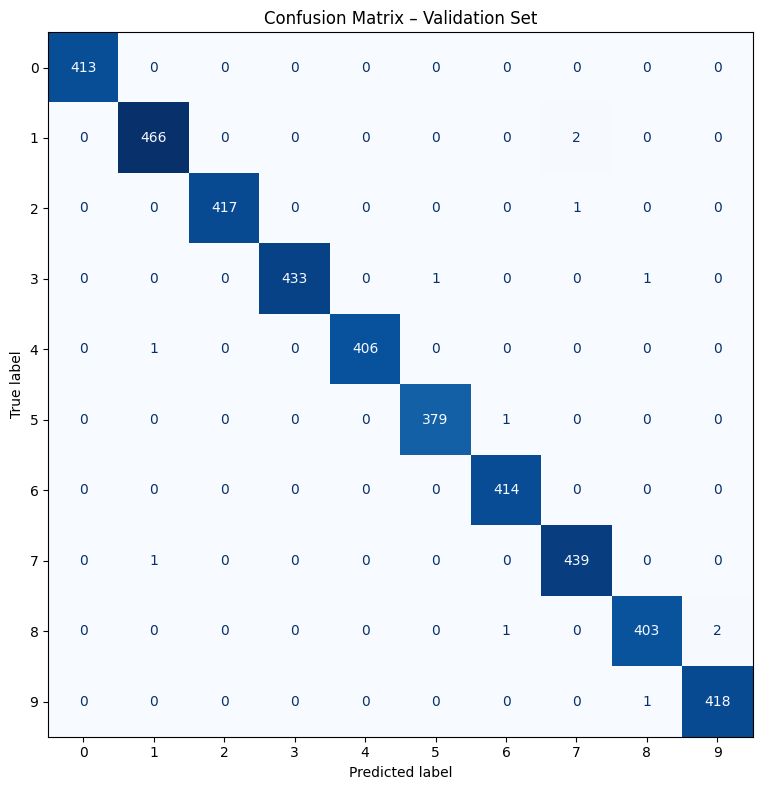

In [20]:
# generate confusion matrix

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Confusion Matrix – Validation Set")
plt.tight_layout()
plt.show()

In [21]:
# generate classification report

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=np.arange(10),
        target_names=[str(i) for i in range(10)],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       413
           1     0.9957    0.9957    0.9957       468
           2     1.0000    0.9976    0.9988       418
           3     1.0000    0.9954    0.9977       435
           4     1.0000    0.9975    0.9988       407
           5     0.9974    0.9974    0.9974       380
           6     0.9952    1.0000    0.9976       414
           7     0.9932    0.9977    0.9955       440
           8     0.9951    0.9926    0.9938       406
           9     0.9952    0.9976    0.9964       419

    accuracy                         0.9971      4200
   macro avg     0.9972    0.9972    0.9972      4200
weighted avg     0.9971    0.9971    0.9971      4200



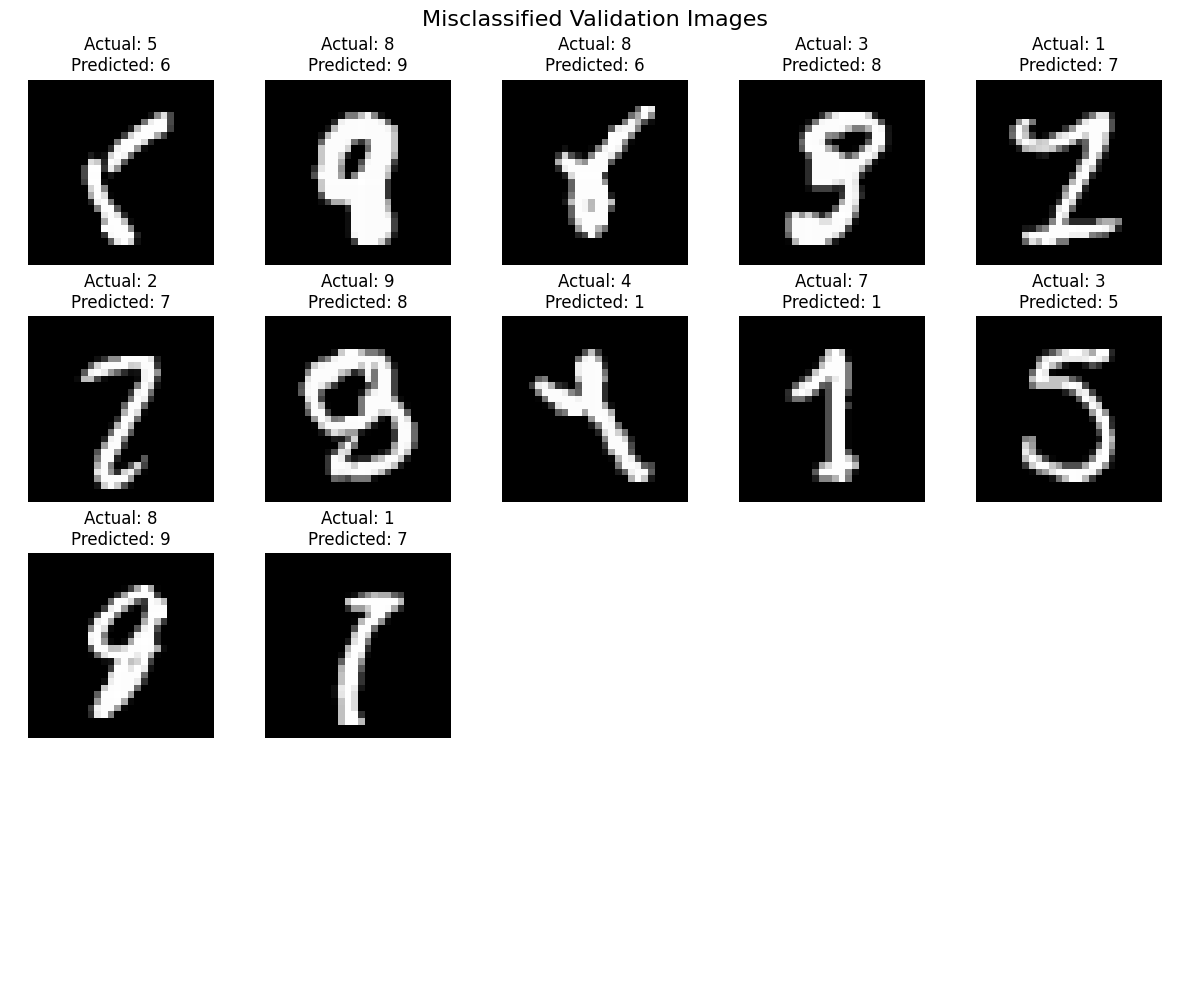

In [22]:
# visualize misclassified images

fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for i, ax in enumerate(axes.flat):

    if i < len(misclassified_images):

        img = misclassified_images[i].squeeze().numpy()

        # if the image has multiple channels, use the first.
        if img.ndim == 3:
            img = img[0]

        # reverse normalization
        img = img * 0.5 + 0.5

        ax.imshow(img, cmap="gray", vmin=0, vmax=1)

        ax.set_title(
            f"Actual: {misclassified_labels[i]}\n"
            f"Predicted: {misclassified_predictions[i]}"
        )

    ax.axis("off")

plt.suptitle("Misclassified Validation Images", fontsize=16)
plt.tight_layout()
plt.show()


In [23]:
# do the predictions on the test set

pred_list = []

print(df_test.shape)

im_id_list = np.arange(1, df_test.shape[0] + 1)

with torch.no_grad():

    for i, data in enumerate(test_loader, 0):

        images, _ = data
        images = images.to(device)

        outputs = Net(images)

        _, predicted = torch.max(outputs, 1)

        pred_list.extend(predicted.tolist())

(28000, 784)


In [24]:
# calculate and verify validation accuracy

accuracy = (np.array(all_predictions) == np.array(all_labels)).mean() * 100

print(f"Validation accuracy: {accuracy:.4f}%")
print(f"Correct predictions: {sum(np.array(all_predictions) == np.array(all_labels))}")
print(f"Incorrect predictions: {sum(np.array(all_predictions) != np.array(all_labels))}")

Validation accuracy: 99.7143%
Correct predictions: 4188
Incorrect predictions: 12


In [ ]:
submission = pd.DataFrame({"ImageId": im_id_list, "Label": pred_list})

In [26]:
submission.to_csv("submission.csv", index=False)